# 推理计时：把重复准备移出循环

目标：在相同固定随机动作头、相同输入、相同精度下，比较“每次构建归一化常量并搬运输入”与“复用常量和输入缓冲区”。输出为同步后的每调用毫秒数、中位数及数值误差。

练习使用6维观测与20×7动作的小型动作头，无训练、无需下载权重。它帮助定位数据准备和调度成本；实际机器人策略仍需要完整观测处理与动作接口。

## 准备环境与计时器
图形计算调用可能异步返回；计时器在测量前后同步设备，交替测量两种实现，预热8次、5轮各100次。

**本次原生设备实测：0.06508 → 0.04629 毫秒，1.406倍；计时单位为每次小型动作头调用。正确性检查通过。**


In [1]:
from pathlib import Path
import json, hashlib, platform, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the course root from a source or exported notebook directory.
COURSE = next(p for p in [Path.cwd(), *Path.cwd().parents]
              if (p / "reproducibility/task-catalog.json").is_file())
EVIDENCE = COURSE / "notebooks/results/acceleration"
plt.rcParams.update({"figure.figsize": (8, 3.5), "font.size": 11})
print({"python": platform.python_version(), "evidence": str(EVIDENCE)})

import torch
torch.manual_seed(7)
torch.set_num_threads(2)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device_record = {"torch": torch.__version__, "hip": torch.version.hip,
                 "device": str(DEVICE),
                 "name": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else platform.processor(),
                 "scope": "small fixed random action-head exercise; no robot policy or task score"}
display(device_record)
# Six-dimensional observation -> twenty seven-dimensional actions.
model = torch.nn.Sequential(torch.nn.Linear(6, 128), torch.nn.ReLU(),
                            torch.nn.Linear(128, 128), torch.nn.ReLU(),
                            torch.nn.Linear(128, 140)).to(DEVICE).eval()
observation = np.array([[0.1, -0.2, 0.3, 0.0, 0.1, -0.1]], dtype=np.float32)
mean = np.array([[0.0, 0.1, 0.2, 0.0, 0.0, 0.0]], dtype=np.float32)
scale = np.array([[0.2, 0.3, 0.1, 1.0, 1.0, 1.0]], dtype=np.float32)
def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

def paired_timings(functions, repeats=5, calls=100):
    # Alternate order to limit warm-cache and temperature order effects.
    samples = {name: [] for name in functions}
    for f in functions.values():
        for _ in range(8):
            f()
    synchronize()
    for repeat in range(repeats):
        names = list(functions)
        if repeat % 2:
            names.reverse()
        for name in names:
            synchronize()
            start = time.perf_counter()
            for _ in range(calls):
                functions[name]()
            synchronize()
            samples[name].append((time.perf_counter() - start) * 1000 / calls)
    return samples

print(json.loads((EVIDENCE / "amd-device-20261028-v1/device.json").read_text()))


{'python': '3.10.19', 'evidence': '/dev/shm/amd-acceleration-20261028-v1/course/notebooks/results/acceleration'}


{'torch': '2.11.0+rocm7.13.0a20260425',
 'hip': '7.13.26162',
 'device': 'cuda',
 'name': 'Radeon 8060S Graphics',
 'scope': 'small fixed random action-head exercise; no robot policy or task score'}

{'hostname': 'aup-NucBox-EVO-X2', 'python': '3.10.19 (main, Oct 21 2025, 16:43:05) [GCC 11.2.0]', 'torch': '2.11.0+rocm7.13.0a20260425', 'hip': '7.13.26162', 'gpu': 'Radeon 8060S Graphics', 'remote_reported_time': '2026-10-29T03:40:02.777923+08:00', 'work_mount': '/dev/shm', 'work_free_bytes': 18131025920, 'scope': 'shared AMD device; other services left running; no training or robot task evaluation'}


## 先读一次真实策略的首次准备与稳态记录
这份灵巧手诊断完成了20个适配器张量的严格加载，准备发生在正式回合之前。下面只从保存的真实记录计算统计量。

{'pre_episode_preparation_s': 17.84689265099587,
 'saved_inference_calls': 51,
 'saved_steady_median_ms': 897.0902384899091,
 'scope': 'one correctly loaded prewarmed baseline diagnostic; official scheduling and termination unchanged; excluded from formal denominators'}

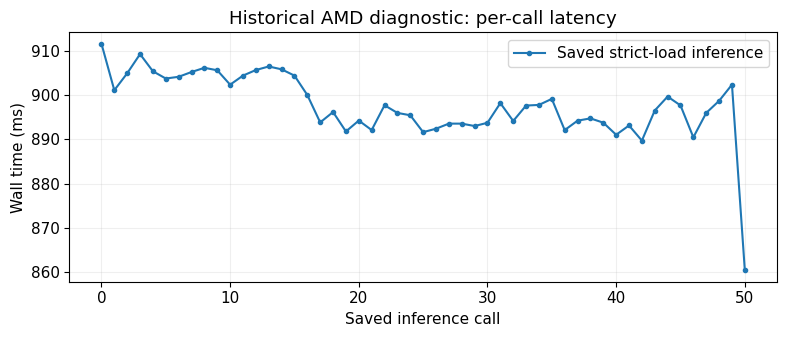

In [2]:
historical = json.loads((EVIDENCE / "strict_latency_summary.json").read_text())
warmup = json.loads((EVIDENCE / "strict_latency_warmup.json").read_text())
audit = json.loads((EVIDENCE / "strict_latency_model_load_audit.json").read_text())
assert audit["adapter_tensor_count"] == 20
times = np.asarray(historical["inference_wall_ms"], dtype=float)
assert np.isfinite(times).all()
display({"pre_episode_preparation_s": warmup["seconds"],
         "saved_inference_calls": len(times),
         "saved_steady_median_ms": historical["steady_inference_median_ms"],
         "scope": historical["scope"]})
fig, ax = plt.subplots()
ax.plot(np.arange(len(times)), times, marker=".", label="Saved strict-load inference")
ax.set(xlabel="Saved inference call", ylabel="Wall time (ms)", title="Historical AMD diagnostic: per-call latency")
ax.grid(alpha=.2); ax.legend(); fig.tight_layout(); plt.show()


## 动手修改数据准备
基准函数每次分配归一化常量、搬运输入；改进函数保留常量与输入缓冲区。输入每次仍通过复制更新，避免把真实数据更新成本漏出计时。两者均使用 `torch.inference_mode()`，不改变模型或动作块长度。

{'median_ms': {'Repeated preparation': 0.06507864920422435,
  'Reused buffers': 0.04629313014447689},
 'raw_round_ms': {'Repeated preparation': [0.06568804965354502,
   0.06549604004248977,
   0.06503293989226222,
   0.06507864920422435,
   0.06501654046587646],
  'Reused buffers': [0.046466230414807796,
   0.04629313014447689,
   0.046171030262485147,
   0.04629822913557291,
   0.04591722972691059]},
 'speed_ratio': 1.4057949635533278,
 'max_abs_output_error': 0.0,
 'device': {'torch': '2.11.0+rocm7.13.0a20260425',
  'hip': '7.13.26162',
  'device': 'cuda',
  'name': 'Radeon 8060S Graphics',
  'scope': 'small fixed random action-head exercise; no robot policy or task score'}}

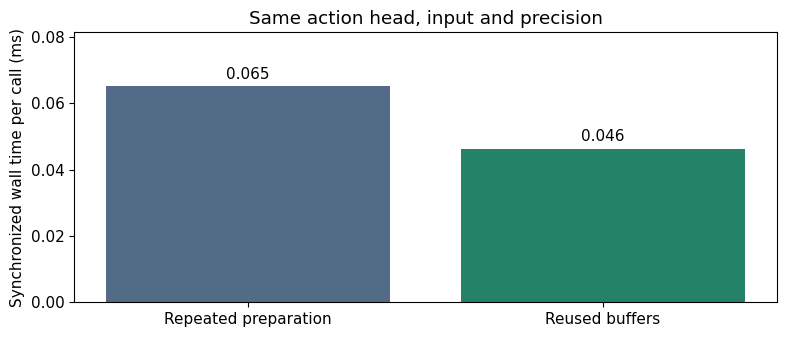

In [3]:
host_observation = torch.from_numpy(observation)
device_mean = torch.as_tensor(mean, device=DEVICE)
device_scale = torch.as_tensor(scale, device=DEVICE)
input_buffer = torch.empty_like(host_observation, device=DEVICE)
@torch.inference_mode()
def repeated_prepare():
    value = torch.as_tensor(observation, device=DEVICE)
    center = torch.as_tensor(mean, device=DEVICE)
    spread = torch.as_tensor(scale, device=DEVICE)
    return model((value - center) / spread)
@torch.inference_mode()
def reuse_buffers():
    input_buffer.copy_(host_observation)
    return model((input_buffer - device_mean) / device_scale)

reference = repeated_prepare().clone()
candidate = reuse_buffers().clone()
torch.testing.assert_close(reference, candidate, rtol=1e-5, atol=1e-6)
samples = paired_timings({"Repeated preparation": repeated_prepare, "Reused buffers": reuse_buffers})
medians = {k: float(np.median(v)) for k, v in samples.items()}
display({"median_ms": medians, "raw_round_ms": samples,
         "speed_ratio": medians["Repeated preparation"] / medians["Reused buffers"],
         "max_abs_output_error": (reference-candidate).abs().max().item(),
         "device": device_record})
fig, ax = plt.subplots()
ax.bar(medians.keys(), medians.values(), color=["#526b87", "#238267"])
ax.set(ylabel="Synchronized wall time per call (ms)", title="Same action head, input and precision")
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set_ylim(0, max(medians.values()) * 1.25); fig.tight_layout(); plt.show()


## 检查与练习
1. 把每轮调用次数从100改为300，检查中位数是否稳定。
2. 修改观测值，重新运行数值一致性检查；保留输入更新。
3. 将真实策略中的图像缩放、设备传输、策略前向、动作反归一化分别包进相同计时器，再优化占比最高的部分。

某种修改是否加速由上面的实测比值决定；同设备共享负载也会影响结果。首次编译、预热、稳态前向和闭环成功率各自记录。